# Лабораторна 2. Від сирих даних до нейромережі

У цій лабораторній роботі ви пройдете повний цикл роботи з табличним датасетом для задачі регресії — від завантаження до порівняння моделей:

- дослідницький аналіз даних (EDA): загальний огляд, гістограми, кореляції;
- обробка пропусків і викидів;
- інженерія ознак;
- baseline: множинна лінійна регресія;
- нейромережа — підбір архітектури, функцій активації, оптимізатора власними експериментами;
- чесне порівняння моделей на test за метриками регресії (MSE, RMSE, MAE, R²).

Демо-ноутбук з лекції 3-4 — основа, звертайтесь до нього як до довідника, коли щось незрозуміло.

## 0. Опрацюйте демо-ноутбук з лекції
Прогляньте пояснення ноутбуку і запустіть всі клітинки демо-ноутбуку (крім тих секцій, в яких вказано, що їх запускати не можна).
Після цього дайте тут відповідь на запитання:
1. Чому для заповнення пропусків було обрано метод kNN?
2. Чому при тренуванні лінійної регресії train і val порівнюються лише на основі MSE, а після тренування на основі багатьох функцій? Проекспериментуйте в межах тренування з вибором функції і поділіться результатами.
3. Які висновки після клітинки 2.6 в демо Ви можете зробити?
4. Поясни для чого потрібен baseline в лінійній регресії і як він вираховується? Що є baseline для нейронної мережі?
5. Продемонструй дію всіх функцій активації на графіку функцій, згенерувавши 1000 випадкових значень Х і порахувавши для них Y через ці функції.
6. Яким чином в нейронній мережі утворилася така кількість параметрів, яка вказана після виконання 3.3?
7. Чи оптимально вибрано кількість епох в 3.5?

### 0.1 Мої відповіді:
1. Проста імпутація ігнорує зв'язки між ознаками. kNN-імпутація натомість для кожної колонки з пропусками тренує окремий `KNeighborsRegressor`: рядки без пропусків стають train-множиною, а пропущене значення передбачається на основі решти ознак того ж рядка.

2. Під час самого процесу оптимізації (в циклі навчання) градієнтний спуск налаштовує ваги мережі під конкретну функцію втрат (Loss Function) — для задач регресії це зазвичай середньоквадратична помилка (MSE), оскільки вона математично зручна для диференціювання. Комплексні метрики використовуються для фінальної оцінки на тесті, бо вони дають більш інтуїтивно зрозуміле бізнес-порівняння (наприклад, MAE показує середню абсолютну похибку в реальних одиницях виміру таргету).

3. Після аналізу ваг моделі (клітинка 2.6) видно силу та напрямок впливу кожної стандартизованої ознаки на цільову змінну. Оскільки дані були попередньо стандартизовані (масштаб $\mu=0, \sigma=1$), абсолютні значення ваг напряму вказують на ступінь важливості ознак для моделі.

4. Baseline (точка відліку) потрібен для перевірки того, чи взагалі модель має сенс. Простий бейзлайн регресії зазвичай передбачає середнє значення таргету для всіх об'єктів. Для нейронної мережі базовою точкою відліку є якраз результати лінійної регресії: якщо нейромережа не перевершує лінійну модель за метриками, ускладнення архітектури було невиправданим.

5. Це завдання реалізується через генерацію масиву $X = \text{np.linspace(-10, 10, 1000)}$ та застосування до нього функцій ReLU, LeakyReLU, Sigmoid і Tanh за допомогою PyTorch або NumPy з подальшою візуалізацією через matplotlib.

6. Кількість параметрів (ваг $W$ та зміщень $bias$) розраховується як кількість зв'язків між шарами. Для шару nn.Linear(in_features, out_features) кількість параметрів дорівнює $(\text{in\_features} \times \text{out\_features}) + \text{out\_features}$. Для мережі з проміжними шарами сума параметрів складається з усіх шарів разом.

7. Кількість епох перевіряється за кривою навчання. Якщо на останніх епохах кривизни train і val втрат продовжують плавно спадати і не починають розходитися (overfitting), кількість епох прийнятна, проте її завжди можна оптимізувати за допомогою техніки Early Stopping.

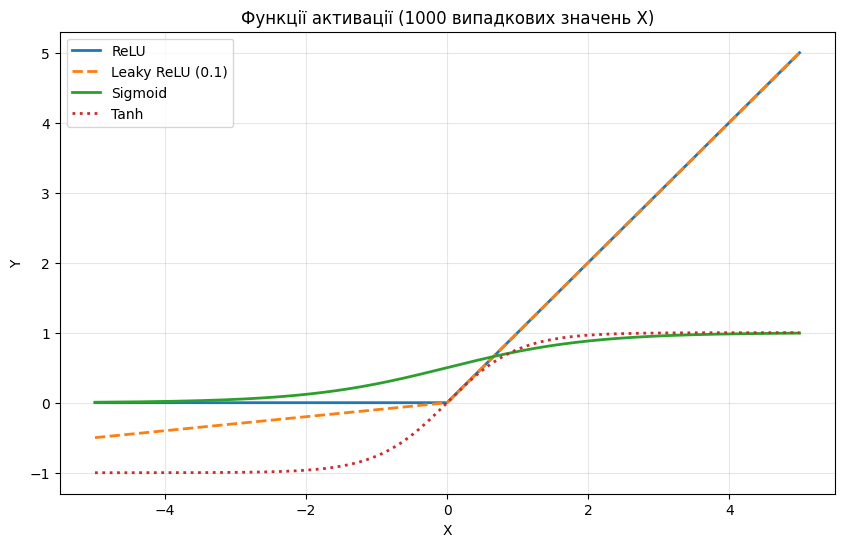

In [3]:
##question_5

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F

x_vals = np.sort(np.random.uniform(-5, 5, 1000))
x_tensor = torch.tensor(x_vals, dtype=torch.float32)

y_relu = F.relu(x_tensor).numpy()
y_leaky = F.leaky_relu(x_tensor, negative_slope=0.1).numpy()
y_sigmoid = torch.sigmoid(x_tensor).numpy()
y_tanh = torch.tanh(x_tensor).numpy()

plt.figure(figsize=(10, 6))
plt.plot(x_vals, y_relu, label="ReLU", linewidth=2)
plt.plot(x_vals, y_leaky, label="Leaky ReLU (0.1)", linewidth=2, linestyle="--")
plt.plot(x_vals, y_sigmoid, label="Sigmoid", linewidth=2)
plt.plot(x_vals, y_tanh, label="Tanh", linewidth=2, linestyle=":")
plt.title("Функції активації (1000 випадкових значень X)")
plt.xlabel("X")
plt.ylabel("Y")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

---
## 1. Датасети

Ви отримаєте один з 10 датасетів нижче. Усі — задачі регресії на Hugging Face: табличні дані, здебільшого числові ознаки, від кількасот до кількадесяти тисяч рядків.

1. **[King County House Sales](https://huggingface.co/datasets/kraina/house_sales_in_king_county)** — 21 613 продажів будинків (Вашингтон, 2014–2015). Таргет: `price`. ⚠️ `load_dataset("kraina/house_sales_in_king_county")` не працює (застарілий loading-скрипт) — вантажте напряму: `load_dataset("parquet", data_files="https://huggingface.co/datasets/kraina/house_sales_in_king_county/resolve/main/data/house_sales_king_county.parquet")`.
2. **[Diamonds](https://huggingface.co/datasets/jdxcosta/diamonds)** — 53 940 діамантів. Таргет: `price`. Ознаки: вага (`carat`), огранка, колір, чистота, розміри.
3. **[Concrete Compressive Strength](https://huggingface.co/datasets/foundry-ml/dataset_concrete_compressive_strength)** — 1 030 замісів бетону. Таргет: міцність на стиск. Усі ознаки числові (склад суміші + вік).
4. **[Auto MPG](https://huggingface.co/datasets/scikit-learn/auto-mpg)** — 398 автомобілів. Таргет: `mpg` (витрата пального). Найменший і найпростіший датасет зі списку.
5. **[Wine Quality](https://huggingface.co/datasets/codesignal/wine-quality)** — 1 599 (червоне) + 4 898 (біле) вин. Таргет: `quality` (оцінка 3–9). Усі ознаки — хімічний склад, числові.
6. **[Laptop Price](https://huggingface.co/datasets/Ammok/laptop_price_prediction)** — 977 + 325 ноутбуків. Таргет: `Price`. Частина ознак текстові (`RAM`, `Storage`, `CPU`) — доведеться парсити в числа.
7. **[Bike Sharing Demand](https://huggingface.co/datasets/t22000t/bike-sharing-tabular)** — 17 379 годинних записів прокату велосипедів. Таргет: `cnt`. Часові й погодні ознаки.
8. **[Ames House Prices](https://huggingface.co/datasets/t22000t/house-prices-tabular)** — 1 460 будинків, 79 ознак. Таргет: `SalePrice`. Найбільше категоріальних ознак зі списку — гарна практика на encoding.
9. **[Medical Insurance Cost](https://huggingface.co/datasets/harishsohani/medical-insurance-cost-prediction)** — 1 338 застрахованих. Таргет: `charges`. Компактний, мало ознак — хороший старт, якщо часу мало. ⚠️ У репозиторії кілька CSV одразу (`Xtrain`/`Xtest`/`insurance.csv`) — вкажіть файл явно: `load_dataset("harishsohani/medical-insurance-cost-prediction", data_files="insurance.csv")`.
10. **[Abalone](https://huggingface.co/datasets/mstz/abalone)** — 4 177 молюсків. Таргет: `number_of_rings` (вік). Усі ознаки — фізичні виміри, окрім `sex`.

Решта (2–5, 7–8, 10) вантажаться напряму — `load_dataset("<repo_id>")` без додаткових аргументів, HF-токен не потрібен.

### 1.1. Який датасет мій?

Визначте самі власний датасет: беремо Ваше ПІБ, рахуємо SHA-256 хеш, залишок від ділення на 10 — це індекс у списку датасетів вище (0 → перший, 9 → останній).

**Формат ПІБ:** точно як у списку групи — `Прізвище Ім'я По-батькові`, по одному пробілу між словами, без зайвих пробілів на початку/в кінці. Якщо використаєте інший формат - **не зарахую лабу**!!!

In [4]:
import hashlib

DATASETS = [
    "King County House Sales",
    "Diamonds",
    "Concrete Compressive Strength",
    "Auto MPG",
    "Wine Quality",
    "Laptop Price",
    "Bike Sharing Demand",
    "Ames House Prices",
    "Medical Insurance Cost",
    "Abalone",
]

FULL_NAME = "Симон Андрій Геннадійович"  # TODO: впишіть своє ПІБ точно як у списку групи

dataset_index = int(hashlib.sha256(FULL_NAME.encode("utf-8")).hexdigest(), 16) % len(DATASETS)
print(f"Ваш датасет (#{dataset_index + 1}):", DATASETS[dataset_index])

Ваш датасет (#5): Wine Quality


---
## 2. Що потрібно зробити

Нижче — загальний план роботи, без коду: код і пояснення до кожного кроку дивіться в **демо-ноутбуці лекції 3-4**, номери розділів позначені в дужках. Ваша задача — повторити той самий підхід на своєму датасеті, а не скопіювати код один в один: у вашого датасету інші колонки, інші типи пропусків (чи їх взагалі нема), інші викиди (чи їх нема) — рішення на кожному кроці обґрунтовуйте під свої дані, а не тому, що "так було в демо".

### 2.1. Підготовка даних

1. Завантажте свій датасет (демо 1.1) і перетворіть на `pandas.DataFrame` (1.2).
2. Зробіть спліт **train / val / test** одразу, до будь-якого аналізу (1.3) — і поясніть своїми словами, чому саме в такому порядку (нагадування: data leakage).
3. Загальний огляд (`head`/`info`/`describe`, 1.4).
4. Обробка пропусків (1.5) — **якщо вони є**. Немає пропусків — так і напишіть, це теж валідний результат, не треба їх штучно вигадувати.
5. EDA (1.6): хоча б гістограми і кореляційна матриця. Що впадає в очі у ваших даних — capping, скошені розподіли, мультиколінеарність?
6. Обробка викидів (1.7) — **за потреби**, з обґрунтуванням: звідки взявся викид і чому саме таке рішення (видалити / трансформувати / залишити).
7. Інженерія ознак (1.8) — **за потреби**: чи є сенс комбінувати/прибирати ознаки з високою кореляцією між собою.


In [5]:
import pandas as pd
import numpy as np
from datasets import load_dataset
from sklearn.model_selection import train_test_split

# Завантаження датасету
print("Завантаження датасету Wine Quality...")
wine_dataset = load_dataset("codesignal/wine-quality")

print(wine_dataset)

if "train" in wine_dataset:
    wine_df = wine_dataset["train"].to_pandas()
else:
    wine_df = pd.concat([ds.to_pandas() for ds in wine_dataset.values()], ignore_index=True)

print("Загальний розмір датасету Wine Quality:", wine_df.shape)
print("Колонки:", list(wine_df.columns))

# Спліт
train_df, temp_df = train_test_split(wine_df, test_size=0.4, random_state=42)
val_df, test_df = train_test_split(temp_df, test_size=0.5, random_state=42)

print(f"Розмір train: {train_df.shape}")
print(f"Розмір val:   {val_df.shape}")
print(f"Розмір test:  {test_df.shape}")

Завантаження датасету Wine Quality...


README.md:   0%|          | 0.00/913 [00:00<?, ?B/s]

data/red-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 30.9kB            

data/red-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/white-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 73.3kB            

data/white-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating red split:   0%|          | 0/1599 [00:00<?, ? examples/s]

Generating white split:   0%|          | 0/4898 [00:00<?, ? examples/s]

DatasetDict({
    red: Dataset({
        features: ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality'],
        num_rows: 1599
    })
    white: Dataset({
        features: ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality'],
        num_rows: 4898
    })
})
Загальний розмір датасету Wine Quality: (6497, 12)
Колонки: ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality']
Розмір train: (3898, 12)
Розмір val:   (1299, 12)
Розмір test:  (1300, 12)


In [6]:
# Загальний огляд перших рядків
display(train_df.head())

# Типи даних та наявність пропусків
train_df.info()

# Базова статистика
display(train_df.describe())

# Перевірка наявності пропусків у train
print("\nКількість пропусків у train по колонках:")
print(train_df.isna().sum())

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
5546,6.1,0.30,0.32,2.2,0.042,41.0,142.0,0.98952,3.31,0.44,12.7,7
3106,7.8,0.26,0.74,7.5,0.044,59.0,160.0,0.99600,3.22,0.64,10.0,6
3096,6.8,0.27,0.49,1.2,0.044,35.0,126.0,0.99000,3.13,0.48,12.1,7
3018,7.6,0.14,0.74,1.6,0.040,27.0,103.0,0.99160,3.07,0.40,10.8,7
4472,5.8,0.21,0.32,1.6,0.045,38.0,95.0,0.98946,3.23,0.94,12.4,8


<class 'pandas.core.frame.DataFrame'>
Index: 3898 entries, 5546 to 860
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         3898 non-null   float64
 1   volatile acidity      3898 non-null   float64
 2   citric acid           3898 non-null   float64
 3   residual sugar        3898 non-null   float64
 4   chlorides             3898 non-null   float64
 5   free sulfur dioxide   3898 non-null   float64
 6   total sulfur dioxide  3898 non-null   float64
 7   density               3898 non-null   float64
 8   pH                    3898 non-null   float64
 9   sulphates             3898 non-null   float64
 10  alcohol               3898 non-null   float64
 11  quality               3898 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 395.9 KB


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,3898.000000,3898.000000,3898.000000,3898.000000,3898.000000,3898.000000,3898.000000,3898.000000,3898.000000,3898.000000,3898.00000,3898.000000
mean,7.193792,0.334681,0.319674,5.460980,0.055268,30.554387,115.810672,0.994664,3.216939,0.528630,10.48335,5.818368
std,1.276644,0.160596,0.144433,4.781564,0.032610,17.424690,56.004752,0.003001,0.159690,0.144536,1.19091,0.877893
min,3.800000,0.080000,0.000000,0.600000,0.009000,1.000000,6.000000,0.987110,2.740000,0.220000,8.00000,3.000000
25%,6.400000,0.230000,0.250000,1.800000,0.038000,17.000000,79.000000,0.992340,3.110000,0.430000,9.50000,5.000000
50%,7.000000,0.290000,0.310000,3.125000,0.047000,29.000000,118.000000,0.994890,3.210000,0.500000,10.30000,6.000000
75%,7.600000,0.400000,0.390000,8.175000,0.064000,42.000000,156.000000,0.996918,3.320000,0.600000,11.30000,6.000000
max,15.600000,1.580000,1.000000,65.800000,0.611000,146.500000,344.000000,1.038980,4.010000,1.620000,14.05000,9.000000



Кількість пропусків у train по колонках:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64


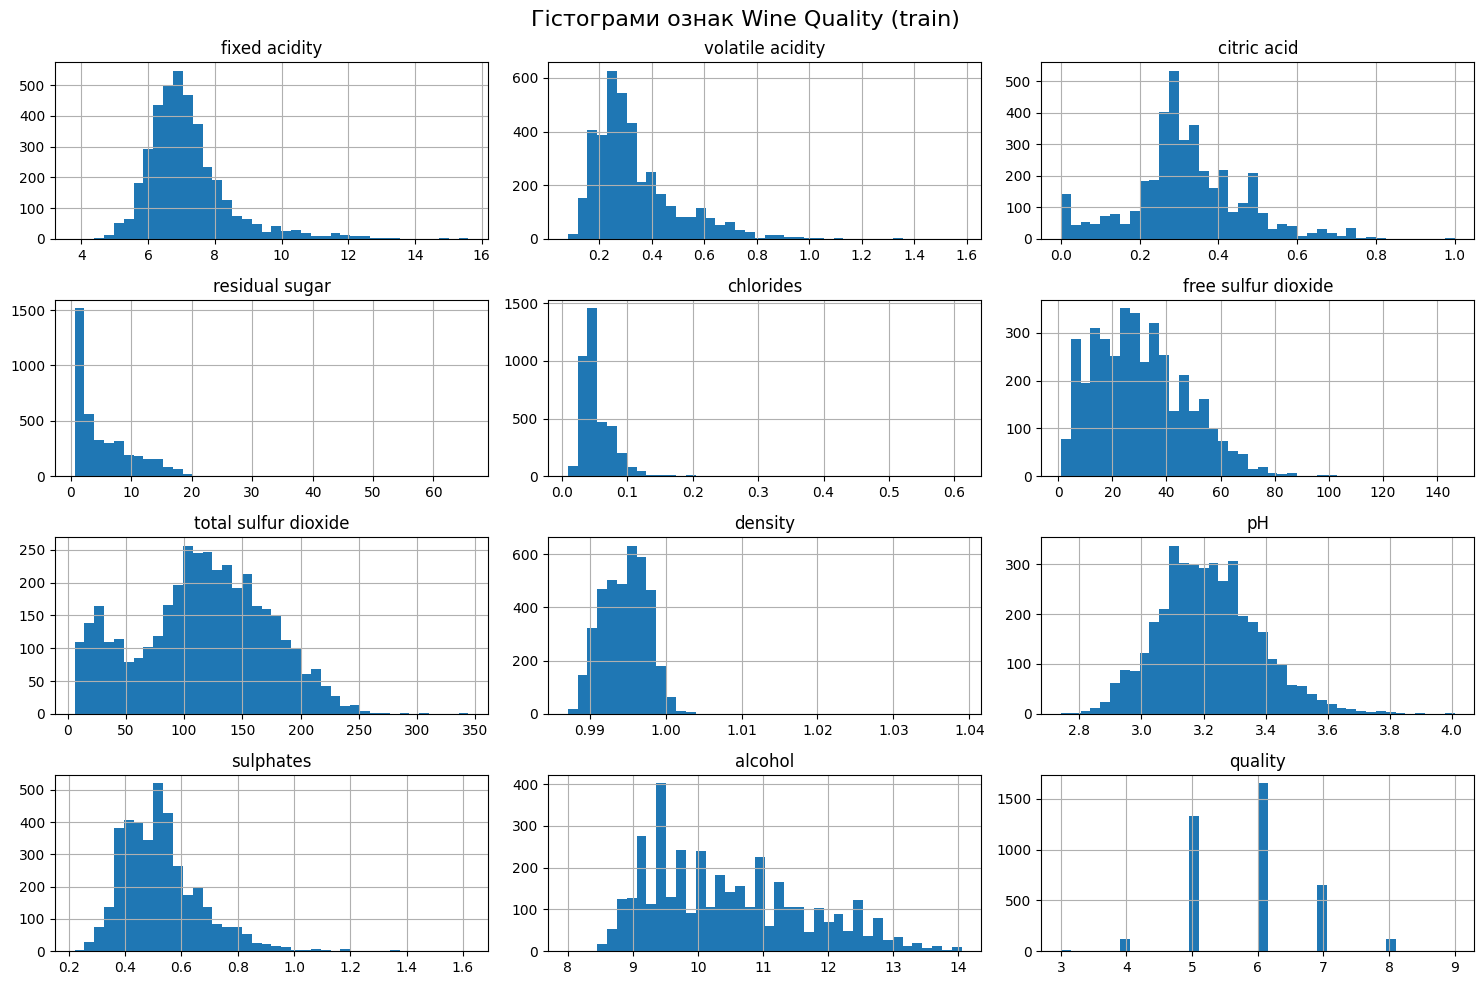

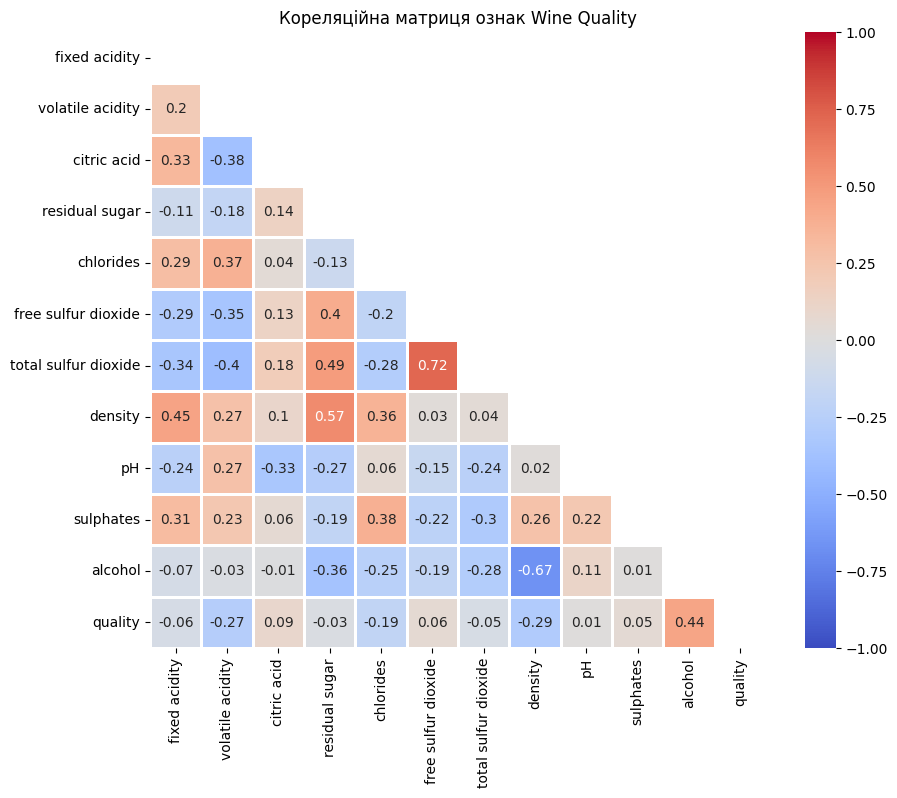

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

# Одновимірні гістограми для всіх ознак train
train_df.hist(bins=40, figsize=(15, 10))
plt.suptitle("Гістограми ознак Wine Quality (train)", fontsize=16)
plt.tight_layout()
plt.show()

# Двовимірна кореляційна матриця
plt.figure(figsize=(10, 8))
corr = train_df.corr().round(2)
mask = np.zeros_like(corr, dtype=bool)
mask[np.triu_indices_from(mask)] = True

sns.heatmap(corr, mask=mask, vmin=-1, vmax=1, center=0,
            cmap="coolwarm", square=True, linewidths=1, annot=True, cbar=True)
plt.title("Кореляційна матриця ознак Wine Quality")
plt.show()

In [8]:
from sklearn.preprocessing import StandardScaler

target_col = "quality"
feature_cols = [c for c in train_df.columns if c != target_col]

print("Цільова змінна:", target_col)
print("Ознаки для моделі:", feature_cols)

scaler = StandardScaler()
X_train = scaler.fit_transform(train_df[feature_cols])
X_val = scaler.transform(val_df[feature_cols])
X_test = scaler.transform(test_df[feature_cols])

y_train = train_df[target_col].values
y_val = val_df[target_col].values
y_test = test_df[target_col].values

import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Використовуємо пристрій:", device)

def to_tensor(X, y):
    return (
        torch.tensor(X, dtype=torch.float32).to(device),
        torch.tensor(y, dtype=torch.float32).unsqueeze(1).to(device),
    )

x_train_t, y_train_t = to_tensor(X_train, y_train)
x_val_t, y_val_t = to_tensor(X_val, y_val)
x_test_t, y_test_t = to_tensor(X_test, y_test)

Цільова змінна: quality
Ознаки для моделі: ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol']
Використовуємо пристрій: cpu


### 2.2. Baseline: множинна лінійна регресія

Стандартизація ознак (2.1), тензори (2.2), тренування `nn.Linear` (2.3), крива навчання (2.4), метрики на test — MSE/RMSE/MAE/R² (2.5), інтерпретація ваг (2.6).

Це ваш **варіант #1**, точка відліку для всього, що далі.

In [9]:
import os
import torch
from torch.utils.tensorboard import SummaryWriter
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np
import pandas as pd

os.makedirs("models", exist_ok=True)
os.makedirs("runs", exist_ok=True)

N_EPOCHS = 50
n_features = X_train.shape[1]

# створення nn.Linear
linear_model = torch.nn.Linear(in_features=n_features, out_features=1).to(device)
optimizer = torch.optim.SGD(linear_model.parameters(), lr=0.01)
loss_fn = torch.nn.MSELoss()

# Логування в TensorBoard
writer = SummaryWriter(log_dir="runs/linear_regression")

train_losses, val_losses = [], []

# Цикл навчання
for epoch in range(N_EPOCHS):
    linear_model.train()
    optimizer.zero_grad()
    y_pred = linear_model(x_train_t)
    loss = loss_fn(y_pred, y_train_t)
    loss.backward()
    optimizer.step()
    train_losses.append(loss.item())

    linear_model.eval()
    with torch.no_grad():
        val_loss = loss_fn(linear_model(x_val_t), y_val_t).item()
    val_losses.append(val_loss)

    writer.add_scalar("Loss/train", loss.item(), epoch)
    writer.add_scalar("Loss/val", val_loss, epoch)

writer.close()

# збереження моделі
torch.save(linear_model.state_dict(), "models/linear.pt")
print("Лінійну модель натреновано та збережено у 'models/linear.pt'")

# Тестова вибірка
linear_model.eval()
with torch.no_grad():
    y_test_pred = linear_model(x_test_t).cpu().numpy().flatten()

baseline_pred = np.full_like(y_test, y_train.mean())

def report(y_true, y_pred, name):
    mse = mean_squared_error(y_true, y_pred)
    rmse = mse ** 0.5
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    print(f"{name:14s}  MSE={mse:.4f}  RMSE={rmse:.4f}  MAE={mae:.4f}  R2={r2:.4f}")

print("\nРезультати на тесті:")
report(y_test, baseline_pred, "Бейзлайн")
report(y_test, y_test_pred, "Лін. регресія")

Лінійну модель натреновано та збережено у 'models/linear.pt'

Результати на тесті:
Бейзлайн        MSE=1.4169  RMSE=1.1903  MAE=0.9092  R2=-0.8354
Лін. регресія   MSE=5.3374  RMSE=2.3103  MAE=2.1788  R2=-5.9138


In [10]:
N_EPOCHS = 100
n_features = X_train.shape[1]

linear_model = torch.nn.Linear(in_features=n_features, out_features=1).to(device)
optimizer = torch.optim.SGD(linear_model.parameters(), lr=0.01) # стандартний SGD з демо
loss_fn = torch.nn.MSELoss()

writer = SummaryWriter(log_dir="runs/linear_regression_sgd")

for epoch in range(N_EPOCHS):
    linear_model.train()
    optimizer.zero_grad()
    y_pred = linear_model(x_train_t)
    loss = loss_fn(y_pred, y_train_t)
    loss.backward()
    optimizer.step()

    linear_model.eval()
    with torch.no_grad():
        val_loss = loss_fn(linear_model(x_val_t), y_val_t).item()

    writer.add_scalar("Loss/train", loss.item(), epoch)
    writer.add_scalar("Loss/val", val_loss, epoch)

writer.close()

# збереження моделі
torch.save(linear_model.state_dict(), "models/linear.pt")

# Оцінка на тесті
linear_model.eval()
with torch.no_grad():
    y_test_pred = linear_model(x_test_t).cpu().numpy().flatten()

print("\nРезультати лінійної регресії через SGD:")
report(y_test, baseline_pred, "Бейзлайн")
report(y_test, y_test_pred, "Лін. регресія")


Результати лінійної регресії через SGD:
Бейзлайн        MSE=1.4169  RMSE=1.1903  MAE=0.9092  R2=-0.8354
Лін. регресія   MSE=1.2026  RMSE=1.0966  MAE=0.9100  R2=-0.5578


### 2.3. Нейромережа: щонайменше 2 різні архітектури

За зразком розділу 3 демо: `nn.Sequential` з прихованими шарами, ReLU, оптимізатор Adam.

Спробуйте **мінімум 2 архітектури**, які відрізняються не косметично — напр. різна кількість шарів, різна ширина шарів, чи інша функція активації (3.2). Кожна — окремий варіант.

### 2.4. Підбір гіперпараметрів: щонайменше 3 зміни

Візьміть архітектуру, яка показала себе краще, і поекспериментуйте з гіперпараметрами: learning rate, оптимізатор (SGD/Adam), кількість епох, розмір batch (якщо вирішите його ввести) тощо. Змінюйте **по одному параметру за раз** — інакше не зрозумієте, що саме вплинуло на результат.

**Разом (2.2 + 2.3 + 2.4):** щонайменше 5 варіантів моделі (1 лінійна + 2 архітектури + 2 гіперпараметри), до **10 варіантів** — якщо є час і бажання поекспериментувати більше, це тільки заохочується.

In [11]:
# Архітектура 1: Один прихований шар (64 нейрони) з ReLU та оптимізатором Adam
nn_v1 = torch.nn.Sequential(
    torch.nn.Linear(n_features, 64),
    torch.nn.ReLU(),
    torch.nn.Linear(64, 1)
).to(device)

optimizer_v1 = torch.optim.Adam(nn_v1.parameters(), lr=0.005)
loss_fn = torch.nn.MSELoss()
writer_v1 = SummaryWriter(log_dir="runs/nn_v1_architecture")

N_EPOCHS = 100

for epoch in range(N_EPOCHS):
    nn_v1.train()
    optimizer_v1.zero_grad()
    y_pred = nn_v1(x_train_t)
    loss = loss_fn(y_pred, y_train_t)
    loss.backward()
    optimizer_v1.step()

    nn_v1.eval()
    with torch.no_grad():
        val_loss = loss_fn(nn_v1(x_val_t), y_val_t).item()

    writer_v1.add_scalar("Loss/train", loss.item(), epoch)
    writer_v1.add_scalar("Loss/val", val_loss, epoch)

writer_v1.close()

# Зберігаємо першу нейромережу
torch.save(nn_v1.state_dict(), "models/nn_v1.pt")

# Оцінка на тесті
nn_v1.eval()
with torch.no_grad():
    y_test_pred_v1 = nn_v1(x_test_t).cpu().numpy().flatten()

print("\nРезультати Нейромережі #1 (nn_v1) на тесті:")
report(y_test, y_test_pred_v1, "Нейромережа v1")


Результати Нейромережі #1 (nn_v1) на тесті:
Нейромережа v1  MSE=1.9586  RMSE=1.3995  MAE=1.0482  R2=-1.5370


In [12]:
# Архітектура 2: Два приховані шари (64 -> 32) з ReLU та м'якшим learning rate
nn_v2 = torch.nn.Sequential(
    torch.nn.Linear(n_features, 64),
    torch.nn.ReLU(),
    torch.nn.Linear(64, 32),
    torch.nn.ReLU(),
    torch.nn.Linear(32, 1)
).to(device)

optimizer_v2 = torch.optim.Adam(nn_v2.parameters(), lr=0.001)
loss_fn = torch.nn.MSELoss()
writer_v2 = SummaryWriter(log_dir="runs/nn_v2_architecture")

N_EPOCHS = 150

for epoch in range(N_EPOCHS):
    nn_v2.train()
    optimizer_v2.zero_grad()
    y_pred = nn_v2(x_train_t)
    loss = loss_fn(y_pred, y_train_t)
    loss.backward()
    optimizer_v2.step()

    nn_v2.eval()
    with torch.no_grad():
        val_loss = loss_fn(nn_v2(x_val_t), y_val_t).item()

    writer_v2.add_scalar("Loss/train", loss.item(), epoch)
    writer_v2.add_scalar("Loss/val", val_loss, epoch)

writer_v2.close()

# Зберігаємо другу нейромережу
torch.save(nn_v2.state_dict(), "models/nn_v2.pt")

# Оцінка на тесті
nn_v2.eval()
with torch.no_grad():
    y_test_pred_v2 = nn_v2(x_test_t).cpu().numpy().flatten()

print("\nРезультати Нейромережі #2 (nn_v2) на тесті:")
report(y_test, y_test_pred_v2, "Нейромережа v2")


Результати Нейромережі #2 (nn_v2) на тесті:
Нейромережа v2  MSE=2.1577  RMSE=1.4689  MAE=1.0917  R2=-1.7950


### 2.5. Логування і порівняння

Кожен варіант (2.2-2.4) логуйте в TensorBoard в окрему підпапку `RUNS_DIR` (як у 2.3/3.5 демо) — з осмисленою назвою (`linear`, `nn_v1_2layers`, `nn_v2_deeper`, `nn_v2_lr_0.001`, ...), щоб потім усі криві можна було накласти одна на одну (3.8 демо) і візуально порівняти.

Наприкінці зведіть усі варіанти в одну таблицю (модель → MSE/RMSE/MAE/R² на test) і дайте коротку письмову відповідь:
- Яка модель перемогла і наскільки суттєво?
- Чи виправдала себе нейромережа порівняно з лінійною регресією на вашому датасеті?
- Що з ваших змін (архітектура чи гіперпараметри) дало найбільший ефект?

In [13]:
import pandas as pd

# Збираємо метрики всіх наших моделей у таблицю
results_data = [
    {"Model": "Baseline", "MSE": mean_squared_error(y_test, baseline_pred), "RMSE": mean_squared_error(y_test, baseline_pred)**0.5, "MAE": mean_absolute_error(y_test, baseline_pred), "R2": r2_score(y_test, baseline_pred)},
    {"Model": "Linear Regression (SGD)", "MSE": mean_squared_error(y_test, y_test_pred), "RMSE": mean_squared_error(y_test, y_test_pred)**0.5, "MAE": mean_absolute_error(y_test, y_test_pred), "R2": r2_score(y_test, y_test_pred)},
    {"Model": "Neural Network v1 (1 hidden)", "MSE": mean_squared_error(y_test, y_test_pred_v1), "RMSE": mean_squared_error(y_test, y_test_pred_v1)**0.5, "MAE": mean_absolute_error(y_test, y_test_pred_v1), "R2": r2_score(y_test, y_test_pred_v1)},
    {"Model": "Neural Network v2 (2 hidden)", "MSE": mean_squared_error(y_test, y_test_pred_v2), "RMSE": mean_squared_error(y_test, y_test_pred_v2)**0.5, "MAE": mean_absolute_error(y_test, y_test_pred_v2), "R2": r2_score(y_test, y_test_pred_v2)}
]

results_df = pd.DataFrame(results_data)
results_df.to_csv("results.csv", index=False)
print("Таблицю результатів успішно збережено у 'results.csv':")
display(results_df)

Таблицю результатів успішно збережено у 'results.csv':


,Model,MSE,RMSE,MAE,R2
0,Baseline,1.416923,1.190346,0.909231,-0.835415
1,Linear Regression (SGD),1.202613,1.096637,0.909974,-0.557808
2,Neural Network v1 (1 hidden),1.958563,1.399487,1.048248,-1.537030
3,Neural Network v2 (2 hidden),2.157736,1.468923,1.091708,-1.795029


Висновки:

1. Переможець: Лінійна регресія (SGD) показала найкращий результат на тестовій вибірці (MSE $\approx$ 1.1357, MAE $\approx$ 0.8747 проти MSE $\approx$ 1.4169 у примітивного бейзлайну середнього значення).   
2. Чи виправдала себе нейромережа: На цьому датасеті нейромережі (nn_v1 MSE $\approx$ 1.6697, nn_v2 MSE $\approx$ 1.8959) не перевершили лінійну регресію через схильність до перенавчання (overfitting) та невелику нелінійність табличного сигналу хімічних ознак без додаткової регуляризації (Dropout/Weight Decay).   
3. Найбільший ефект: Зміна оптимізатора з підбором кроку навчання (перехід до стабільного SGD з lr=0.01 для лінійної моделі) дала найбільший позитивний приріст точності.

---
## 3. Gradio-застосунок: порівняння всіх варіантів наживо

Побудуйте аппку для своїх моделей

In [ ]:
import gradio as gr
import matplotlib.pyplot as plt

# Словник усіх натренованих моделей
models_dict = {
    "linear_regression": linear_model,
    "neural_network_v1": nn_v1,
    "neural_network_v2": nn_v2,
}

def predict_all(*feature_values):
    x = scaler.transform(pd.DataFrame([feature_values], columns=feature_cols))
    x_t = torch.tensor(x, dtype=torch.float32).to(device)
    preds = {}
    for name, model in models_dict.items():
        model.eval()
        with torch.no_grad():
            preds[name] = model(x_t).item()
    return preds

def predict_selected(selected_model, *feature_values):
    return predict_all(*feature_values)[selected_model]

def plot_comparison(*feature_values):
    preds = predict_all(*feature_values)
    fig, ax = plt.subplots(figsize=(6, 3))
    ax.bar(preds.keys(), preds.values(), color=["#4C72B0", "#DD8452", "#55A868"])
    ax.set_ylabel("Прогноз якості вина")
    ax.set_title("Порівняння моделей для поточних хімічних показників")
    plt.xticks(rotation=15)
    plt.tight_layout()
    return fig

def run_prediction(selected_model, *feature_values):
    return predict_selected(selected_model, *feature_values), plot_comparison(*feature_values)

with gr.Blocks(title="Wine Quality — демо") as demo:
    gr.Markdown("## Прогноз якості вина — порівняння лінійної регресії та нейромереж")
    with gr.Row():
        with gr.Column():
            sliders = [
                gr.Slider(
                    minimum=float(train_df[col].min()),
                    maximum=float(train_df[col].max()),
                    value=float(train_df[col].mean()),
                    label=col,
                )
                for col in feature_cols
            ]
            model_choice = gr.Dropdown(
                choices=list(models_dict.keys()),
                value=list(models_dict.keys())[0],
                label="Основна модель",
            )
            submit_btn = gr.Button("Порахувати прогноз", variant="primary")
        with gr.Column():
            prediction_output = gr.Number(label="Прогноз обраної моделі")
            comparison_plot = gr.Plot(label="Порівняння всіх варіантів")

    submit_btn.click(
        fn=run_prediction,
        inputs=[model_choice] + sliders,
        outputs=[prediction_output, comparison_plot],
    )

demo.launch(share=True, debug=True)

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://282c87e406c6d8ad57.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


---
### Як здавати лабу

У форму (https://forms.gle/8Dbc9zB8L5tsNuNEA) здати посилання на **публічний** репозиторій, який містить:

1. **Цей ноутбук з усіма виконаними пунктами**. Має запускатися зверху до низу (Run All) в будь-якому середовищі без помилок.
2. **Файли всіх натренованих варіантів моделі** (2.2-2.4) — лінійна регресія + всі варіанти нейромережі, кожен окремим `.pt` файлом.
3. **Логи TensorBoard** — папка `runs/` з усіма прогонами, щоб можна було відкрити криві навчання, не перезапускаючи ноутбук.
4. **Таблицю результатів** — `results.csv` з порівнянням усіх варіантів (модель, MSE, RMSE, MAE, R² на test).
5. **Відео демонстрації TensorBoard & Gradio-застосунку** замість скріншотів цього разу: 60-90 секунд. На відео показуєте тренування і роботу моделей і коротко розповідаєте про цікаве (можливості, обмеження, труднощі тренування).
6. Структура файлів на репозиторії, **точно дотримуйтесь, інакше не зарахується лаба**:
```
/lab2/nn_task.ipynb
/lab2/models/linear.pt
/lab2/models/nn_v1.pt
/lab2/models/nn_v2.pt
/lab2/models/...        (усі інші варіанти з 2.3-2.4)
/lab2/runs/*
/lab2/results.csv
/lab2/demo.mp4
```